In [1]:
from src.parametric_estimation import ParametricEstimation
from src.motivating_example import MotivatingExample

import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error

from collections.abc import Callable
from typing import Optional

from joblib import Parallel, delayed

import nlopt

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 


### Choose parameters

In [15]:
n = 2000
d = 2

eps = 1e-2
Ycol = 0
methods = ['generation', 'imputation', 'complete', 'complete-case', 'nmmipw', 'gmm_ipw']

if d == 2:
    coef_true = torch.tensor([0, 0.7])
elif d == 3:
    coef_true = torch.tensor([0, 0.7, 0])

### Set up classes

In [3]:
motexp = MotivatingExample(type='mar', n=n, d=d)

### Run experiments

In [4]:
def job(
        eps: float = None, # clamping scale
        Ycol:int = None, # which variable
        methods: list = None
    ):
    X = motexp.get_X()
    M = motexp.get_M(X)
    pe = ParametricEstimation(X=X, M=M)

    # generate test data to compute regression accuracy
    XX = motexp.get_X()
    Xtest = XX[:, np.arange(XX.shape[1]) != Ycol % XX.shape[1]]
    Ytest = XX[:, Ycol]

    out = {}
    for method in methods:
        lin_reg = pe.linear_regression(Ycol=Ycol, method=method, eps=eps)
        coef = np.concatenate(([lin_reg.intercept_], lin_reg.coef_))
        err = mean_squared_error(lin_reg.predict(Xtest), Ytest)
        out[method] = (coef, err)
    return out

In [5]:
B = 50 # CHANGE

results = Parallel(n_jobs=-1)(
    delayed(job)(
        eps=eps,
        Ycol=Ycol,
        methods=methods
    )
    for _ in range(B)
)
    
coef_est = {m: [r[m][0] for r in results] for m in methods}
mse      = {m: [r[m][1] for r in results] for m in methods}

During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C" 
4: Setting LC_MONETARY failed, using "C" 
5: Setting LC_PAPER failed, using "C" 
6: Setting LC_MEASUREMENT failed, using "C" 
During startup - Warning messages:
1: Setting LC_COLLATE failed, using "C" 
2: Setting LC_TIME failed, using "C" 
3: Setting LC_MESSAGES failed, using "C"

### Plot function

In [6]:
def plot_coefficient_boxplots(results, coef_names=None, coef=None, coef_label="True value",
                              coef_color="black", ncols=3, ax_size=(4.2, 3.4),
                              show_points=False, save_path=None):
    """
    results:     dict {method: [array_run1, array_run2, ...]}, each array holds the coefficient estimates
    coef_names:  optional list of labels for the coefficients (default: "Coef 0", "Coef 1", ...)
    coef:        optional array (one value per coefficient); coef[j] is drawn as a horizontal
                 dashed line in panel j
    coef_label:  legend label for that line
    coef_color:  color of that line
    show_points: overlay the individual runs (recommended when there are few runs per method)
    """
    methods = list(results.keys())
    data = {m: np.vstack(results[m]) for m in methods}          # (n_runs, n_coefs) per method
    n_coefs = data[methods[0]].shape[1]
    if coef_names is None:
        coef_names = [f"Coef {j}" for j in range(n_coefs)]
 
    if coef is not None:
        coef = np.asarray(coef, dtype=float).ravel()
        if len(coef) != n_coefs:
            raise ValueError(f"coef has {len(coef)} values but the results have {n_coefs} coefficients.")
 
    nrows = int(np.ceil(n_coefs / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ax_size[0] * ncols, ax_size[1] * nrows),
                             squeeze=False)
    axes_flat = axes.ravel()
    rng = np.random.default_rng(0)
    colors = plt.cm.tab10(np.arange(len(methods)) % 10)
    # colors = ['#ff7f0e'] + ['#4C72B0'] * (len(methods)-1) 
 
    for j in range(n_coefs):
        ax = axes_flat[j]
        vals = [data[m][:, j] for m in methods]
        bp = ax.boxplot(vals, positions=np.arange(1, len(methods) + 1), widths=0.6,
                        patch_artist=True, medianprops=dict(color="black"), showfliers=False)
        for patch, c in zip(bp["boxes"], colors):
            patch.set_facecolor(c)
            # patch.set_alpha(0.45)
 
        if show_points:
            for i, v in enumerate(vals, start=1):
                ax.scatter(i + rng.uniform(-0.12, 0.12, size=len(v)), v,
                           s=14, color="black", zorder=3, alpha=0.8)
 
        if coef is not None:
            ax.axhline(coef[j], color=coef_color, linestyle="--", linewidth=1.2,
                       label=coef_label, zorder=2)
 
        ax.axhline(0, color="gray", linewidth=0.5, zorder=0)
        ax.set_title(coef_names[j])
        ax.set_xticks(np.arange(1, len(methods) + 1))
        ax.set_xticklabels(methods, rotation=45, ha="right")
        ax.grid(axis="y", alpha=0.3)
 
    if coef is not None:
        axes_flat[0].legend(loc="best", fontsize=8)
 
    for ax in axes_flat[n_coefs:]:       # hide unused panels
        ax.set_visible(False)
 
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, axes

### Plot results

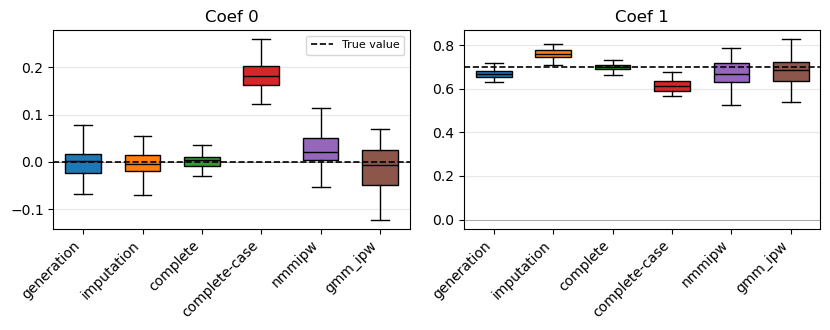

In [16]:
plot_coefficient_boxplots(coef_est, coef=coef_true)
plt.savefig("coef.png")

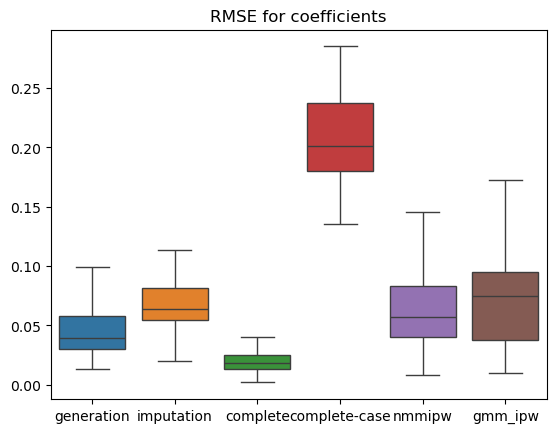

In [19]:
coef_true_np = coef_true.detach().numpy()
rmse_coef = pd.DataFrame({method: [np.linalg.norm(c - coef_true_np) for c in coefs] for method, coefs in coef_est.items()})
sns.boxplot(rmse_coef, showfliers=False)
plt.title("RMSE for coefficients")
plt.savefig("rmse_coef.png")

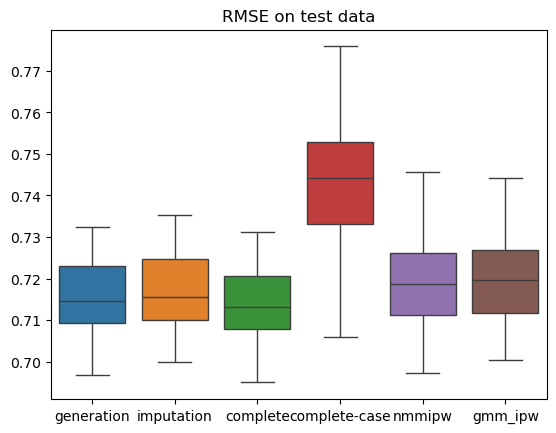

In [20]:
rmse = np.sqrt(pd.DataFrame(mse))
sns.boxplot(rmse, showfliers=False)
plt.title("RMSE on test data")
plt.savefig("rmse.png")